In [107]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from keras.callbacks import EarlyStopping
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [108]:
import zipfile
from keras.utils import image_dataset_from_directory

zipfile.ZipFile("archive.zip").extractall("data")

train_data = image_dataset_from_directory("data/train", image_size=(48,48), color_mode="grayscale", batch_size=64)
test_data = image_dataset_from_directory("data/test", image_size=(48,48), color_mode="grayscale", batch_size=64)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


In [109]:
import numpy as np

def to_arrays(ds):
    X_list, y_list = [], []
    for images, labels in ds:
        X_list.append(images.numpy())
        y_list.append(labels.numpy())
    return np.concatenate(X_list), np.concatenate(y_list)

X_train, y_train = to_arrays(train_data)
X_test, y_test = to_arrays(test_data)

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(28709, 48, 48, 1) (28709,)
(7178, 48, 48, 1) (7178,)


In [110]:
X_train.dtype

dtype('float32')

In [111]:
class_names = train_data.class_names

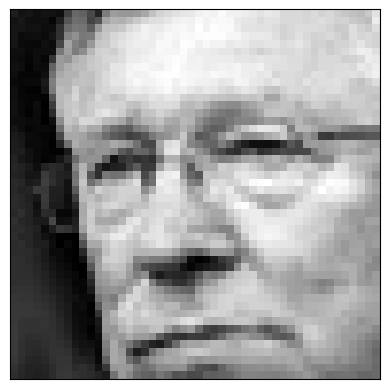

In [112]:
plt.imshow(X_train[1], cmap="gray")
plt.xticks([])
plt.yticks([])
plt.show()

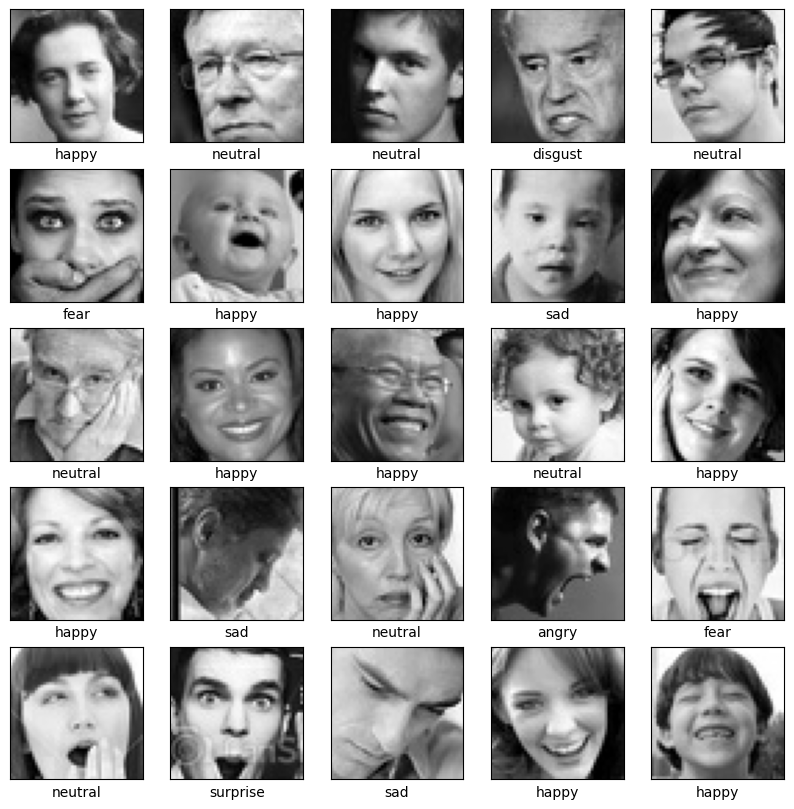

In [113]:
fig_fashion = plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(class_names[y_train[i]])
plt.show()

In [114]:
X_train_scaled = X_train/255
X_test_scaled  = X_test/255

In [115]:
from sklearn.utils import compute_class_weight
c_weights = compute_class_weight(class_weight="balanced",
                                  classes=np.unique(y_train),
                                  y=y_train)
c_weights = dict(enumerate(c_weights))
c_weights

{0: np.float64(1.0266046844269623),
 1: np.float64(9.406618610747051),
 2: np.float64(1.0010460615781582),
 3: np.float64(0.5684387684387684),
 4: np.float64(0.8260394187886635),
 5: np.float64(0.8491274770777877),
 6: np.float64(1.293372978330405)}

In [131]:
model = Sequential([
                    Flatten(input_shape=(48, 48, 1)),

                    Dense(500, activation='relu'),
                    Dense(400, activation='relu'),
                    Dense(300, activation='relu'),
                    Dense(200, activation='relu'),
                    Dense(100, activation='relu'),
                    Dense(7, activation='softmax')
                    ])


model.summary()


model.compile(optimizer="adam", loss='sparse_categorical_crossentropy', metrics=['acc'])


history = model.fit(X_train_scaled, y_train, validation_split=0.2, epochs=10)

Model: "sequential_14"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_14 (Flatten)            │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_62 (Dense)                │ (None, 500)            │     1,152,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_63 (Dense)                │ (None, 400)            │       200,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_64 (Dense)                │ (None, 300)            │       120,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_65 (Dense)                │ (None, 200)            │        60,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_66 (Dense)                │ (None, 100)            │        20,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_67 (Dense)                │ (None, 7)              │           707 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,554,207 (5.93 MB)

 Trainable params: 1,554,207 (5.93 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 37s 46ms/step - acc: 0.2641 - loss: 1.7938 - val_acc: 0.2830 - val_loss: 1.7583
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 24ms/step - acc: 0.3128 - loss: 1.7143 - val_acc: 0.3180 - val_loss: 1.7037
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - acc: 0.3359 - loss: 1.6856 - val_acc: 0.3406 - val_loss: 1.6800
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 16s 23ms/step - acc: 0.3478 - loss: 1.6615 - val_acc: 0.3544 - val_loss: 1.6526
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 18s 25ms/step - acc: 0.3589 - loss: 1.6420 - val_acc: 0.3588 - val_loss: 1.6416
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 20s 24ms/step - acc: 0.3620 - loss: 1.6338 - val_acc: 0.3518 - val_loss: 1.6444
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 19s 26ms/step - acc: 0.3630 - loss: 1.6290 - val_acc: 0.3466 - val_loss: 1.6608
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 17s 23ms/step - acc: 0.3618 - loss: 1.6216 - val_acc: 0.3467 - val_loss: 1.6475
Epoch 9/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 

In [132]:
y_pred_test = model.predict(X_test_scaled).argmax(axis=1)
y_pred_test

225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step


array([6, 3, 5, ..., 3, 5, 6])

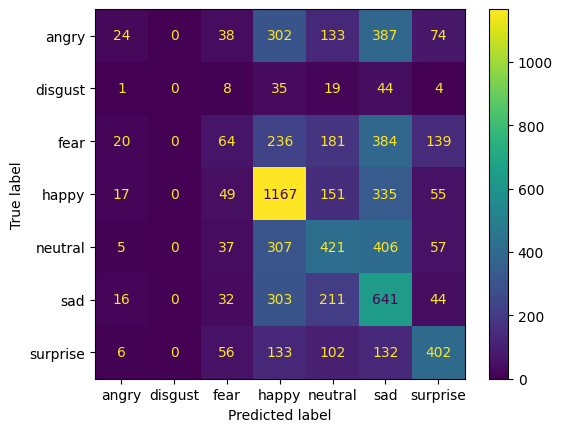

In [133]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test, display_labels=class_names);

In [ ]:
confusion_matrix(y_test, y_pred_test)

In [135]:
model.save("emotion_model.keras")